In [ ]:
# Zachary Katz
# zachary_katz@mines.edu
# 26 October 2026

"""
Plot Figure 4, S3, S4 using output from Figure4.py saved as csv files in the output directory
Figure4.py separate because it was run parallelized on a HPC prior to this plotting notebook.

Radar data from Zenodo 
(https://doi.org/10.5281/zenodo.22982329)

Altimetry-derived lake outlines from Zenodo 
(https://doi.org/10.5281/zenodo.15758711)
Subglacial Cheongsuk Lake Outline at output/lake_outlines/evolving_outlines/David_s1.geojson

DDInSAR and Multivariate lake outlines from KPDC 
(https://dx.doi.org/doi:10.22663/KOPRI-KPDC-00001177)
DDInSAR outline from DDInSAR.zip
Multivariate outline from SLD2_Boundary.zip

Subglacial hydropotential from Zenodo
(https://doi.org/10.5281/zenodo.16243278)

"""

# Imports
import os
import re
import ast
import shapefile
import numpy as np
import pandas as pd
import xarray as xr

import geopandas as gpd
from scipy.spatial import cKDTree


import cartopy.crs as ccrs
from pyproj import CRS, Transformer

import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.path import Path
import matplotlib.colors as colors
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from matplotlib.patches import Ellipse
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

%matplotlib inline

################################################################################
############################## USER-DEFINED PATHS ##############################

# Edit these paths to match your data locations. Suggested paths for _Data folder
# in the main DavidSpecularity repo based on default download names shown below. 

# Radar Data Paths
offset_video_path_1617 = '../_Data/1617_OffsetVideo'
offset_video_path_1819 = '../_Data/1819_OffsetVideo'

# CSV directory containing output from Figure4.py
csv_dir = './output750m_win_250m_ovlp'

#Altimetry-Derived Lake Outlines Paths
evolving_path = '../_Data/David_s1.geojson'

# DDInSAR 2, 2-1, and Multivariate Lake Outlines A,B,C Paths
DDInSAR_path2 = '../_Data/David2.shp'
DDInSAR_path2_1 = '../_Data/David2-1.shp'
pathA = '../_Data/SLD2-A.shp'
pathB = '../_Data/SLD2-B.shp'
pathC = '../_Data/SLD2-C.shp'

# Hydropotential Path
hydro_path = '../_Data/subglacial_hydropotential_Antarctica.nc'

# Output Directory
outdir = './_OutputFigures'
os.makedirs(outdir, exist_ok=True)

############################## USER-DEFINED PATHS ##############################
################################################################################

In [2]:
# Load KRT2 offset video netcdf files
file_paths_1819 = [os.path.join(offset_video_path_1819, f) for f in os.listdir(offset_video_path_1819) if f.endswith('.nc')]
file_paths_1617 = [os.path.join(offset_video_path_1617, f) for f in os.listdir(offset_video_path_1617) if f.endswith('.nc')]

offset_video_radargrams_1819 = []
for f in file_paths_1819:
    offset_video_radargram = xr.open_dataset(f, decode_timedelta=True)
    offset_video_radargrams_1819.append(offset_video_radargram)

offset_video_radargrams_1819.sort(key=lambda x: x.transect_id)
offset_video_radargrams_1819[0]

offset_video_radargrams_1617 = []
for f in file_paths_1617:
    offset_video_radargram = xr.open_dataset(f, decode_timedelta=True)
    offset_video_radargrams_1617.append(offset_video_radargram)

offset_video_radargrams_1617.sort(key=lambda x: x.transect_id)
offset_video_radargrams_1617[0]


# Remove radargram.transect_id for x in ['X21b', 'X27b'] from offsert_video_radargrams_1819
offset_video_radargrams_1819 = [rg for rg in offset_video_radargrams_1819 if not any(x in rg.transect_id for x in ['X21a', 'X27a'])]

len(offset_video_radargrams_1819), len(offset_video_radargrams_1617)

(40, 11)

In [3]:
# Helper function
def ll2xy(lon: list[float], lat: list[float]) -> tuple[list[float], list[float]]:
    """
    Transform coordinates from input geodetic coordinates (lon, lat)
    to output Antarctic Polar Stereographic coordinates (x, y).
    Can also take single floats.

    Parameters
    ----------
    lon: list[float]
         Geodetic longitude in EPSG:4326
    lat: list[float]
         Geodetic latitude in EPSG:4326

    Returns
    -------
    x: list[float]
       Antarctic Polar Stereographic (EPSG:3031) x
    y: list[float]
       Antarctic Polar Stereographic (EPSG:3031) y
    """

    crs_ll = CRS("EPSG:4326")
    crs_xy = CRS("EPSG:3031")
    ll_to_xy = Transformer.from_crs(crs_ll, crs_xy, always_xy=True)
    x, y = ll_to_xy.transform(lon, lat)
    return x, y


In [4]:
# Load Subglacial Lake Cheongsuk shapefile
xs_lake = []
ys_lake = []
for path in [pathA, pathB, pathC]:
    sf = shapefile.Reader(path)
    shapes = sf.shapes()
    for shp in shapes:
        points = shp.points
        x = [p[0] for p in points]
        y = [p[1] for p in points]
    xs_lake.append(x)
    ys_lake.append(y)


In [5]:
# Convert from spatial freq width to doppler width
MS_TO_KMHR = 3.6
for radargram in offset_video_radargrams_1819[:]:
    avg_distance = np.mean(np.diff(radargram['distance'].values))

    time = (radargram['time'][-1] - radargram['time'][0])
    time = time / np.timedelta64(1, 's')
    
    velocity = (radargram['distance'][-1] - radargram['distance'][0]).values / time #m/s
    radargram['avg_velocity']  = velocity

    dt = np.gradient(radargram.time.values.astype('datetime64[ns]').astype('int64')) / 1e9 # seconds
    dd = np.gradient(radargram.distance.values) # meters
    radargram['velocity'] = (('distance',), dd/ dt)

for radargram in offset_video_radargrams_1617[:]:
    avg_distance = np.mean(np.diff(radargram['distance'].values))

    time = (radargram['time'][-1] - radargram['time'][0])
    time = time / np.timedelta64(1, 's')
    
    velocity = (radargram['distance'][-1] - radargram['distance'][0]).values / time #m/s
    radargram['avg_velocity']  = velocity

    dt = np.gradient(radargram.time.values.astype('datetime64[ns]').astype('int64')) / 1e9 # seconds
    dd = np.gradient(radargram.distance.values) # meters
    radargram['velocity'] = (('distance',), dd/ dt)

In [6]:
# Load csv files
def parse_floats(str_list):
    return [float(x) for x in re.findall(r'np\.float64\(([-0-9.eE]+)\)', str_list)]
def parse_arrays(str_list):
    return  [float(x) for x in re.findall(r'array\(([-0-9.eE]+)\)', str_list)]
def parse_ridge_params(str_list):
    str_list = re.sub(r'np\.float64\(([-0-9.eE]+)\)', r'\1', str_list)
    str_list = re.sub(r'np\.int64\(([-0-9]+)\)', r'\1', str_list)
    str_list = re.sub(r'\bnan\b', 'None', str_list)  
     
    return ast.literal_eval(str_list) # Careful with safe parsing

def none_to_nan(dictionary):
    # Recursively replace None with np.nan in dictionary/list
    if isinstance(dictionary, list):
        return [none_to_nan(x) for x in dictionary]

    elif isinstance(dictionary, dict):
        return {k: none_to_nan(v) for k, v in dictionary.items()}

    elif dictionary is None:
        return np.nan

    else:
        return dictionary

plotting_dict_1819_csv = pd.read_csv(os.path.join(csv_dir, 'plotting_dict_1819.csv'))
plotting_dict_1617_csv = pd.read_csv(os.path.join(csv_dir, 'plotting_dict_1617.csv'))

plotting_dict_1819_csv['x_centers'] = plotting_dict_1819_csv['x_centers'].apply(parse_floats)
plotting_dict_1819_csv['y_centers'] = plotting_dict_1819_csv['y_centers'].apply(parse_floats)
plotting_dict_1819_csv['ridge_params_list'] = plotting_dict_1819_csv['ridge_params_list'].apply(parse_ridge_params)
plotting_dict_1819_csv['velocities'] = plotting_dict_1819_csv['velocities'].apply(parse_arrays)

plotting_dict_1617_csv['x_centers'] = plotting_dict_1617_csv['x_centers'].apply(parse_floats)
plotting_dict_1617_csv['y_centers'] = plotting_dict_1617_csv['y_centers'].apply(parse_floats)
plotting_dict_1617_csv['ridge_params_list'] = plotting_dict_1617_csv['ridge_params_list'].apply(parse_ridge_params)
plotting_dict_1617_csv['velocities'] = plotting_dict_1617_csv['velocities'].apply(parse_arrays)

plotting_dict_1819_csv['ridge_params_list'] = plotting_dict_1819_csv['ridge_params_list'].apply(none_to_nan)
plotting_dict_1617_csv['ridge_params_list'] = plotting_dict_1617_csv['ridge_params_list'].apply(none_to_nan)

plotting_dict_1819 = plotting_dict_1819_csv.to_dict(orient='list')
plotting_dict = plotting_dict_1617_csv.to_dict(orient='list')


In [7]:
velocities_1819 = []
for radargram, center_list in zip(offset_video_radargrams_1819[:], plotting_dict_1819['x_centers'][:]):
    velocities = []
    for center in center_list[:]:
        idx = np.argmin(np.abs(radargram['x'].compute().values - center))
        velocities.append(radargram['velocity'][idx].values)
    
    velocities_1819.append(velocities)
  
velocities_1617 = []
for radargram, center_list in zip(offset_video_radargrams_1617[:], plotting_dict['x_centers'][:]):
    velocities = []
    for center in center_list[:]:
        idx = np.argmin(np.abs(radargram['x'].compute().values - center))
        velocities.append(radargram['velocity'][idx].values)
    
    velocities_1617.append(velocities)  

plotting_dict_1819['velocities'] = velocities_1819
plotting_dict['velocities'] = velocities_1617

In [8]:
# Plot difference

# Find points within 500 m of each other in the two datasets
coords_1819 = np.column_stack((
    np.concatenate(plotting_dict_1819['x_centers']),
    np.concatenate(plotting_dict_1819['y_centers'])
))

coords_1617 = np.column_stack((
    np.concatenate(plotting_dict['x_centers']),
    np.concatenate(plotting_dict['y_centers'])
))

ridge_params_1819 = [r for sublist in plotting_dict_1819['ridge_params_list'] for r in sublist]
ridge_params_1617 = [r for sublist in plotting_dict['ridge_params_list'] for r in sublist]

# Compute width (abs(left-right)) for each sub-point
width_1819 = np.array([abs(r['left'] - r['right']) for r in ridge_params_1819])
width_1617 = np.array([abs(r['left'] - r['right']) for r in ridge_params_1617])

# Compute scaled_width by multiplying by velocity
width_velocity_scaled_1819 = np.concatenate(velocities_1819) * width_1819
width_velocity_scaled_1617 = np.concatenate(velocities_1617) * width_1617

print(len(plotting_dict_1819['x_centers']))
print(len(plotting_dict_1819['y_centers']))
print(len(plotting_dict['x_centers']))
print(len(plotting_dict['y_centers']))
print(len(width_1819))
print(len(width_1617))
print(len(width_velocity_scaled_1819))
print(len(width_velocity_scaled_1617))

tree_1617 = cKDTree(coords_1617)

dist, idx = tree_1617.query(coords_1819)

mask = dist <= 500

matched_coords = coords_1819[mask]
ridge_diff = width_1819[mask] - width_1617[idx[mask]]
ridge_diff_velocity_scaled = width_velocity_scaled_1819[mask] - width_velocity_scaled_1617[idx[mask]]


40
40
11
11
2026
2675
2026
2675


In [9]:
# Crossover error with self
coords = []
width = []
width_velocity_corrected = []
line_id = []
y_at_max = []

all_velocities_1819 = np.concatenate(plotting_dict_1819['velocities'])
avg_velocity_1819 = np.mean(all_velocities_1819)

all_velocities_1617 = np.concatenate(plotting_dict['velocities'])
avg_velocity_1617 = np.mean(all_velocities_1617)

In [10]:
for i, (xs, ys, ridge_list, velocity) in enumerate(zip(
        plotting_dict_1819['x_centers'],
        plotting_dict_1819['y_centers'],
        plotting_dict_1819['ridge_params_list'],
        plotting_dict_1819['velocities'])):

    n = len(xs)

    

    coords.append(np.column_stack((xs, ys)))
    # Extend by the width of each ridge, scaled by velocity
    width_velocity_corrected.extend([abs(r['left'] - r['right']) * velocity[j] for j, r in enumerate(ridge_list)])
    #avg_velocity = np.mean(velocity)
    width.extend([abs(r['left'] - r['right'])*avg_velocity_1819 for r in ridge_list])
    line_id.extend([i]*n)
    y_at_max.extend([r['y_at_max'] for r in ridge_list])


coords = np.vstack(coords)
width = np.array(width)
width_velocity_corrected = np.array(width_velocity_corrected)
line_id = np.array(line_id)
y_at_max = np.array(y_at_max)

tree = cKDTree(coords)

pairs = np.array(list(tree.query_pairs(r=500)))

i, j = pairs[:,0], pairs[:,1]

mask = line_id[i] != line_id[j]

i = i[mask]
j = j[mask]

ridge_diff_1819 = np.abs(width[i] - width[j])
ridge_diff_velocity_corrected_1819 = np.abs(width_velocity_corrected[i] - width_velocity_corrected[j])
y_at_max = np.minimum(y_at_max[i], y_at_max[j])

coords_i = coords[i]
coords_j = coords[j]

x_cross_1819 = (coords[i,0] + coords[j,0]) / 2
y_cross_1819 = (coords[i,1] + coords[j,1]) / 2


mask = y_at_max > 1250
x_cross_1819 = x_cross_1819[mask]
y_cross_1819 = y_cross_1819[mask]
ridge_diff_velocity_corrected_1819 = ridge_diff_velocity_corrected_1819[mask]
ridge_diff_1819 = ridge_diff_1819[mask]

In [11]:
# Crossover error with self
coords = []
width = []
width_velocity_corrected = []
line_id = []
y_at_max = []

for i, (xs, ys, ridge_list, velocity) in enumerate(zip(
        plotting_dict['x_centers'],
        plotting_dict['y_centers'],
        plotting_dict['ridge_params_list'],
        plotting_dict['velocities'])):

    n = len(xs)

    coords.append(np.column_stack((xs, ys)))
    # Extend by the width of each ridge, scaled by velocity
    width_velocity_corrected.extend([abs(r['left'] - r['right']) * velocity[j] for j, r in enumerate(ridge_list)])
    avg_velocity = np.mean(velocity)
    width.extend([abs(r['left'] - r['right'])*avg_velocity_1617 for r in ridge_list])
    line_id.extend([i]*n)
    y_at_max.extend([r['y_at_max'] for r in ridge_list])

coords = np.vstack(coords)
width = np.array(width)
width_velocity_corrected = np.array(width_velocity_corrected)
line_id = np.array(line_id)
y_at_max = np.array(y_at_max)

tree = cKDTree(coords)

pairs = np.array(list(tree.query_pairs(r=500)))

i, j = pairs[:,0], pairs[:,1]

mask = line_id[i] != line_id[j]

i = i[mask]
j = j[mask]

ridge_diff_1617 = np.abs(width[i] - width[j])
ridge_diff_velocity_corrected_1617 = np.abs(width_velocity_corrected[i] - width_velocity_corrected[j])
y_at_max = np.minimum(y_at_max[i], y_at_max[j])

coords_i = coords[i]
coords_j = coords[j]

x_cross = (coords[i,0] + coords[j,0]) / 2
y_cross = (coords[i,1] + coords[j,1]) / 2

mask = y_at_max > 1250
x_cross = x_cross[mask]
y_cross = y_cross[mask]
ridge_diff_velocity_corrected_1617 = ridge_diff_velocity_corrected_1617[mask]
ridge_diff_1617 = ridge_diff_1617[mask]



In [12]:
# Doppler width map with velocity scaling for 2018-2019, 2016-2017, and difference map
# with comparison to satellite lake outlines

# Plot plan view comparison, scaled by velocity
def common_panel_elements(ax, plot_dict, rad_vel):
    """
    Plot doppler width and lake outline map view.
    """

    bbox = [650000,-1475000,680300,-1430000] #David_SGL2_full extent

    # Remove borders
    ax.patch.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

    # Plot scaled widths
    for x_center_list, y_center_list, plotting, velocity in zip((plot_dict['x_centers']),(plot_dict['y_centers']), (plot_dict['ridge_params_list']), (plot_dict['velocities'])): # Use reversed() to switch plotting order
        width = [rp['right'] - rp['left'] for rp in plotting]
        scaled_width = [w * v for w,v in zip(width,velocity)]  # Scale by velocity to get doppler width
        
        y_maxes = np.array([rp['y_at_max'] for rp in plotting])
        mask = y_maxes < 1250
        scaled_width = np.array([sw.item() for sw in scaled_width])
        scaled_width[mask] = np.nan
        
        cb = ax.scatter(x_center_list, y_center_list, c=scaled_width, cmap='viridis', s=30, zorder=4,vmin=0,vmax=25)

    # Add colorbar
    k_cbar_anchor = (0,0)
    cbbox = inset_axes(ax, width=3,height=0.8,
                    bbox_to_anchor=k_cbar_anchor,
                    bbox_transform=ax.transAxes, loc="center left")
    [cbbox.spines[k].set_visible(False) for k in cbbox.spines]
    cbbox.tick_params(
        axis = 'both',
        left = False,
        top = False,
        right = False,
        bottom = False,
        labelleft = False,
        labeltop = False,
        labelright = False,
        labelbottom = False
    )

    cbbox.set_facecolor([0,0,0,0.75])

    cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
    cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal',extend='max') #make colorbar
    cbar.outline.set_edgecolor('white')
    cbar.outline.set_linewidth(1)
    cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
    cbar.set_label(r"Doppler Width [Hz]", fontsize=15, color='white')
    cbar.ax.xaxis.set_label_position('top')

    cbar.ax.minorticks_on()
    cbar.ax.tick_params(axis='x', which='minor',color='white')

    ax.set_xlim(bbox[0],bbox[2])
    ax.set_ylim(bbox[1],bbox[3])
    
    scalebar = AnchoredSizeBar(ax.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
    ax.add_artist(scalebar)

    # Glacial flow arrow
    ax.annotate(
    '',
    xy=(659000, -1436000),      # Tip
    xytext=(664000, -1431000),  # Tail
    arrowprops=dict(
        arrowstyle='-|>',       
        color='black',
        lw=2,
        mutation_scale=20 ,     
    ),
    transform=ps71_projection,
    zorder=10
    )
    ax.text(664000, -1432000, ' Ice Flow\nDirection',
        fontsize=14, color='black', ha='left', va='center',zorder=10)

    return ax


# Load evolving outlines
evolving_outlines = gpd.read_file(f'{evolving_path}')

# Load DDInSAR outlines
path2 = f'{DDInSAR_path2}'
path2_1 = f'{DDInSAR_path2_1}'

DDInSAR_outlines = []
for path in [path2, path2_1]:
    sf = shapefile.Reader(path)
    for shape in sf.shapes():
        points = shape.points
        pts_xy = ll2xy([p[0] for p in points], [p[1] for p in points])
        x, y = pts_xy

        DDInSAR_outlines.append((x, y))


In [13]:
times = evolving_outlines["mid_pt_datetime"]
# Find index of time closest to Jan 25 2017 and Nov 20 2018
target_time_1617 = np.datetime64('2017-01-25T00:00:00')
target_time_1819 = np.datetime64('2018-11-20T00:00:00')

idx_1617 = np.argmin(np.abs(times - target_time_1617))
idx_1819 = np.argmin(np.abs(times - target_time_1819))
print(times[idx_1617], times[idx_1819])

# Plot outlines function
def plot_outlines(ax, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819):
    """Plot outlines for radar, DDInSAR, and Altimetry. Return colors associated with each"""
    colors = []
    # Plot evolving outlines
    for index in [idx_1617, idx_1819]:
        outline = evolving_outlines['geometry'][index]
        time = t_num[index]
        color = cmap(norm(time))
        x_evolve, y_evolve = outline.exterior.xy
        ax.plot(x_evolve, y_evolve, color=color, zorder=5, linewidth=2.5)
        colors.append(color)

    # Plot DDInSAR outlines
    color_DDInSAR = 'black'
    for i, (x, y) in enumerate(DDInSAR_outlines):
        ax.plot(x, y, color=color_DDInSAR, linewidth=2.5, zorder=5)
    colors.append(color_DDInSAR)

    # Plot radar outlines
    color_radar = 'white'
    for x, y in zip(xs_lake, ys_lake):
        ax.plot(x, y, color=color_radar, linewidth=2.5, zorder=5)
    colors.append(color_radar)
    
    # Label radar lakes A, B, C
    ax.annotate('A', xy=(657000, -1446000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
    ax.annotate('B', xy=(664200, -1454000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection, zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
    ax.annotate('C', xy=(668500, -1458000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])

    return colors


2017-01-01 00:00:00 2019-01-01 00:00:00


In [14]:
# Calculate line-km and number of radargrams for each season
def count_radargrams(plotting_dict, radargrams):
    """
    Count the number of radargrams and line-km for a given plotting dictionary.
    """
    radargram_count = 0
    line_km = 0.0
    m_2_km = 1e-3

    for x_center_list in plotting_dict['x_centers']:
        radargram_count += len(x_center_list)

    for radargram in radargrams:
        distance = radargram['distance'][-1]
        line_km += distance.values * m_2_km


    return radargram_count, line_km


radargram_count_1819, line_km_1819 = count_radargrams(plotting_dict_1819, offset_video_radargrams_1819)
radargram_count_1617, line_km_1617 = count_radargrams(plotting_dict, offset_video_radargrams_1617)

print(f"2016-2017: {radargram_count_1617} radargrams, {line_km_1617:.2f} line-km")
print(f"2018-2019: {radargram_count_1819} radargrams, {line_km_1819:.2f} line-km")
    

2016-2017: 2675 radargrams, 1343.38 line-km
2018-2019: 2026 radargrams, 1033.34 line-km


In [15]:
# Load Sauthoff subglacial hydropotential
hydropotential = xr.open_dataset(f'{hydro_path}')
hydropotential = hydropotential.sel(x=slice(620000, 700000), y=slice(-1415000, -1495000))

/tmp/ipykernel_45678/1167380674.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("inferno")


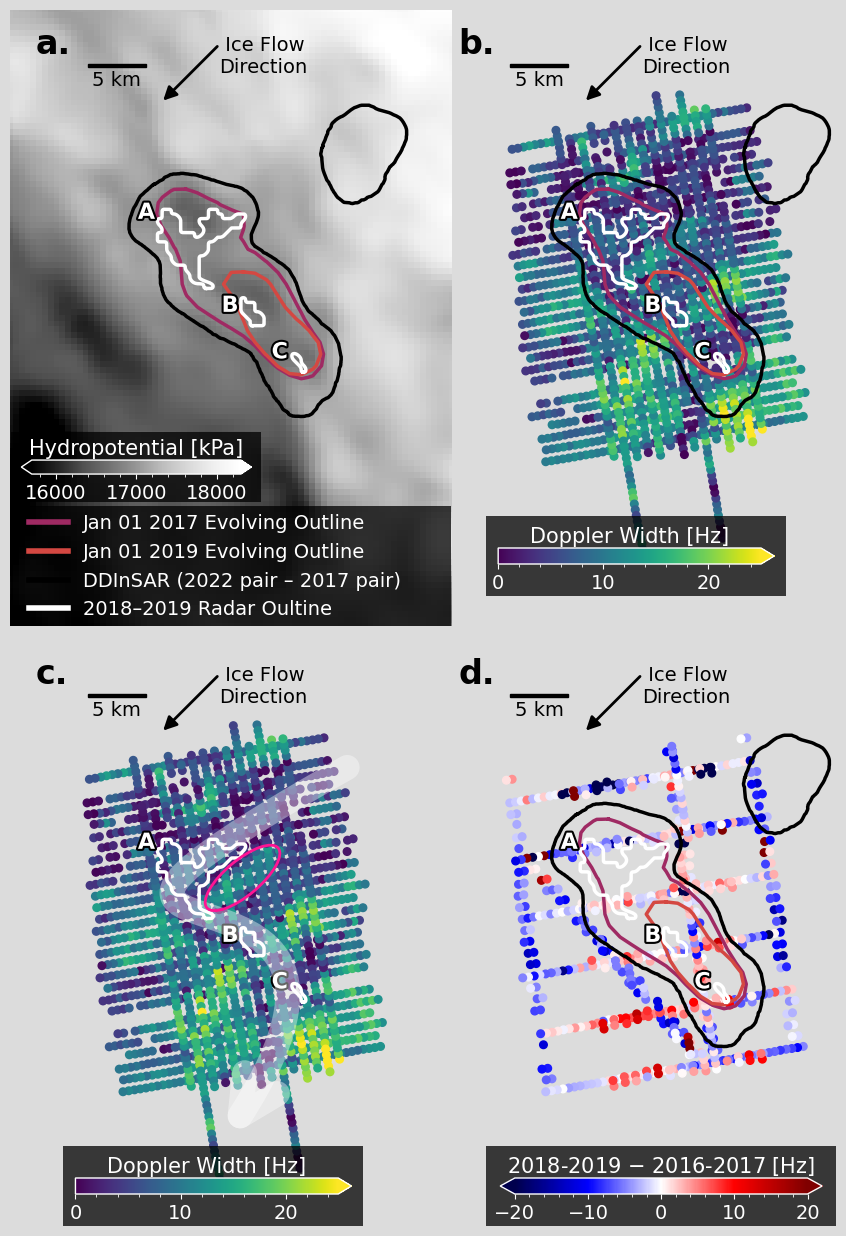

In [16]:
################
### Figure 4 ###
################

ps71_projection = ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-71)
fig, axs = plt.subplots(2,2, figsize=(10,15), subplot_kw={'projection': ps71_projection})
(ax1, ax2, ax3, ax4) = axs.flatten()

# Convert datetimes → numeric (float seconds)
t_num = np.array(times.astype("int64"))  # nanoseconds since epoch

# Normalize to 0–1 range for the colormap
norm = colors.Normalize(vmin=t_num.min(), vmax=t_num.max())
cmap = cm.get_cmap("inferno")
sm = cm.ScalarMappable(norm=norm, cmap=cmap)


## AX1 ##

#common_panel_elements(ax1, plotting_dict, offset_video_radargrams_1617)
bbox = [650000,-1475000,680300,-1430000] #David_SGL2_full extent

# Remove borders
ax1.patch.set_facecolor("none")
for spine in ax1.spines.values():
    spine.set_visible(False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlim(bbox[0],bbox[2])
ax1.set_ylim(bbox[1],bbox[3])

buffer_x = 4000
buffer_y = 6000

x = hydropotential['x']
y = hydropotential['y']

xmask = (x >= bbox[0] - buffer_x) & (x <= bbox[2] + buffer_x)
ymask = (y >= bbox[1] - buffer_y) & (y <= bbox[3] + 2000)

hydropotential = hydropotential.sel(x=xmask, y=ymask)

ax1.set_xlim(bbox[0], bbox[2])
ax1.set_ylim(bbox[1], bbox[3])

pos1 = ax1.get_position()
left1, bottom1, width1, height1 = pos1.bounds
xmin = float(hydropotential.x.min())
xmax = float(hydropotential.x.max())
ymin = float(hydropotential.y.min())
ymax = float(hydropotential.y.max())

bbox_width = bbox[2] - bbox[0]
bbox_height = bbox[3] - bbox[1]

# Full mesh dimensions relative to bbox
mesh_width = width1 * (xmax - xmin) / bbox_width
mesh_height = height1 * (ymax - ymin) / bbox_height
x_offset = width1 * (bbox[0] - xmin) / bbox_width
y_offset = height1 * (bbox[1] - ymin) / bbox_height

mesh_left = left1 - x_offset
mesh_bottom = bottom1 - y_offset

ax_mesh = fig.add_axes(
    [mesh_left, mesh_bottom, mesh_width, mesh_height],
    frameon=False,
    zorder=-1,
)

ax_mesh.set_xlim(xmin, xmax)
ax_mesh.set_ylim(ymin, ymax)

mesh_alpha = 0.9
mesh = ax_mesh.pcolormesh(
    hydropotential.x,
    hydropotential.y,
    hydropotential.subglacial_hydropotential,
    cmap='Grays_r',
    shading='auto',
    zorder=0,
    vmin=15700,
    vmax=18300
)

ax_mesh.set_axis_off()

# Add colorbar
k_cbar_anchor = (-0.148,0.17)
cbbox = inset_axes(ax1, width=2.5,height=0.7,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax1.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)

cbbox.set_facecolor([0,0,0,0.75])

cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(mesh,cax=cbaxes, orientation='horizontal',extend='both') #make colorbar
cbar.set_alpha(mesh_alpha)
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label(r"Hydropotential [kPa]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

cbar.ax.minorticks_on()
cbar.ax.tick_params(axis='x', which='minor',color='white')


scalebar = AnchoredSizeBar(ax1.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
ax1.add_artist(scalebar)

# Glacial flow arrow
ax1.annotate(
'',
xy=(659000, -1436000),      # Tip
xytext=(664000, -1431000),  # Tail
arrowprops=dict(
    arrowstyle='-|>',       
    color='black',
    lw=2,
    mutation_scale=20 ,     
),
transform=ps71_projection,
zorder=10
)
ax1.text(664000, -1432000, ' Ice Flow\nDirection',
    fontsize=14, color='black', ha='left', va='center',zorder=10)



colors_plotted = plot_outlines(ax1, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)

k_cbar_anchor = (-0.148,-0.148) # Bottom right of ax1
cbbox = inset_axes(ax1, width=4.4,height=1.2,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax1.transAxes, loc="lower left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.75])
handles = [
    Line2D([0], [0], color=colors_plotted[0], lw=4, label='Jan 01 2017 Evolving Outline'),
    Line2D([0], [0], color=colors_plotted[1], lw=4, label='Jan 01 2019 Evolving Outline'),
    Line2D([0], [0], color=colors_plotted[2], lw=4, label='DDInSAR (2022 pair – 2017 pair)'),
    Line2D([0], [0], color=colors_plotted[3], lw=4, label='2018\u20132019 Radar Oultine'),
]

# Add legend directly to cbbox
legend = cbbox.legend(
    handles=handles,
    loc='center left',          # center vertically, left horizontally
    bbox_to_anchor=(0.0, 0.5), # tweak horizontal position
    frameon=False,
    fontsize=14,
    labelcolor='white'
)

# Make sure text is white
for text in legend.get_texts():
    text.set_color('white')




## AX2 ##
common_panel_elements(ax2, plotting_dict_1819, offset_video_radargrams_1819)
plot_outlines(ax2, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)

## AX3 ##
common_panel_elements(ax3, plotting_dict_1819, offset_video_radargrams_1819)
# Label radar lakes A, B, C
ax3.annotate('A', xy=(657000, -1446000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax3.annotate('B', xy=(664200, -1454000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection, zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax3.annotate('C', xy=(668500, -1458000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])

# Plot radar outlines
color_radar = 'white'
for x, y in zip(xs_lake, ys_lake):
    ax3.plot(x, y, color=color_radar, linewidth=2.5, zorder=5)

# Arrow path
bbox = [650000,-1475000,680300,-1430000] #David_SGL2_full extent
verts = [
    (675000,-1439000),  # start
    ( 638000,-1460000),  # control 1
    ( 683000,-1442000),  # control 2
    ( 664500,-1471000),  # end
]

path = Path(
    verts,
    [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]
)

arrow = FancyArrowPatch(
    path=path,
    arrowstyle='->',
    mutation_scale=70,
    lw=18,
    color='white',
    zorder=10,
    alpha=0.4
)

ax3.add_patch(arrow)

# Ellipse
ellipse = Ellipse(
    xy=(666000, -1448500),      # center (x, y)
    width=8000,          # major axis
    height=3000,        # minor axis
    angle=40,           # rotation in degrees (counter-clockwise)
    facecolor='none',
    edgecolor='deeppink',
    linewidth=2,
    zorder=10
)

ax3.add_patch(ellipse)


## AX4 ##
# Remove borders
ax4.patch.set_facecolor("none")
for spine in ax4.spines.values():
    spine.set_visible(False)
ax4.set_xticks([])
ax4.set_yticks([])


# Add colorbar
k_cbar_anchor = (0,0)
cbbox = inset_axes(ax4, width=3.5,height=0.8,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax4.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.75])

cb = ax4.scatter(matched_coords[:,0], matched_coords[:,1], c=ridge_diff_velocity_scaled, cmap='seismic', s=30, zorder=4,vmin=-20,vmax=20)
cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal',extend='both') #make colorbar
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label(r"2018-2019 $-$ 2016-2017 [Hz]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

cbar.ax.minorticks_on()
cbar.ax.tick_params(axis='x', which='minor',color='white')

scalebar = AnchoredSizeBar(ax4.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
ax4.add_artist(scalebar)

# Glacial flow arrow
ax4.annotate(
'',
xy=(659000, -1436000),      # Tip
xytext=(664000, -1431000),  # Tail
arrowprops=dict(
    arrowstyle='-|>',       
    color='black',
    lw=2,
    mutation_scale=20 ,     
),
transform=ps71_projection,
zorder=10
)
ax4.text(664000, -1432000, ' Ice Flow\nDirection',
    fontsize=14, color='black', ha='left', va='center',zorder=10)

bbox = [650000,-1475000,680300,-1430000] #David_SGL2_full extent
ax4.set_xlim(bbox[0],bbox[2])
ax4.set_ylim(bbox[1],bbox[3])

plot_outlines(ax4, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)

# Set background gainsboro
fig.patch.set_facecolor('gainsboro')

ax1.text(-0.06, 1.01, 'a.', transform=ax1.transAxes, fontsize=24, fontweight='bold', va='top', ha='left', color='black')
ax2.text(-0.06, 1.01, 'b.', transform=ax2.transAxes, fontsize=24, fontweight='bold', va='top', ha='left', color='black')
ax3.text(-0.06, 1.01, 'c.', transform=ax3.transAxes, fontsize=24, fontweight='bold', va='top', ha='left', color='black')
ax3.text(-0.06, 1.01, 'd.', transform=ax4.transAxes, fontsize=24, fontweight='bold', va='top', ha='left', color='black')


fig.savefig(os.path.join(outdir, 'Figure4.png'), dpi=300, bbox_inches='tight')

/tmp/ipykernel_45678/1131797118.py:97: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("inferno")


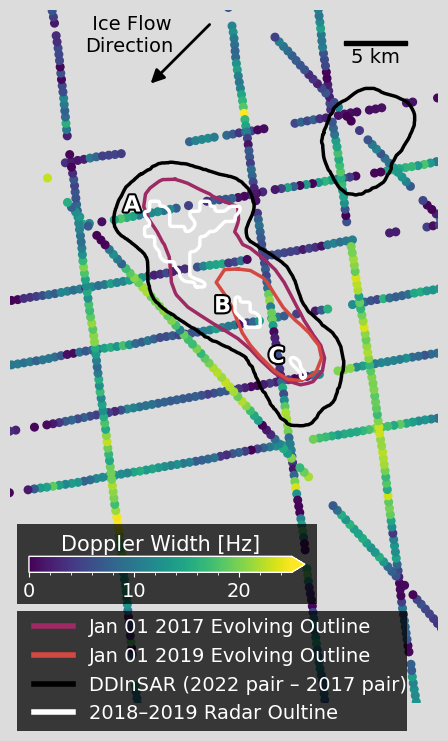

In [17]:
#################
### Figure S6 ###
#################

def common_panel_elements(ax, plot_dict, rad_vel):
    """
    Plot doppler width and lake outline map view.
    """

    bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent

    # Remove borders
    ax.patch.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

    # Plot scaled widths
    for x_center_list, y_center_list, plotting, velocity in zip(reversed(plot_dict['x_centers']),reversed(plot_dict['y_centers']), reversed(plot_dict['ridge_params_list']), reversed(plot_dict['velocities'])):
        width = [rp['right'] - rp['left'] for rp in plotting]
        scaled_width = [w * v for w,v in zip(width,velocity)]  # Scale by velocity to get doppler width
        
        y_maxes = np.array([rp['y_at_max'] for rp in plotting])
        mask = y_maxes < 1250
        scaled_width = np.array([sw.item() for sw in scaled_width])
        scaled_width[mask] = np.nan
        
        cb = ax.scatter(x_center_list, y_center_list, c=scaled_width, cmap='viridis', s=30, zorder=4,vmin=0,vmax=25)

    # Add colorbar
    k_cbar_anchor = (0,0.2)
    cbbox = inset_axes(ax, width=3,height=0.8,
                    bbox_to_anchor=k_cbar_anchor,
                    bbox_transform=ax.transAxes, loc="center left")
    [cbbox.spines[k].set_visible(False) for k in cbbox.spines]
    cbbox.tick_params(
        axis = 'both',
        left = False,
        top = False,
        right = False,
        bottom = False,
        labelleft = False,
        labeltop = False,
        labelright = False,
        labelbottom = False
    )

    cbbox.set_facecolor([0,0,0,0.75])

    cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
    cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal',extend='max') #make colorbar
    cbar.outline.set_edgecolor('white')
    cbar.outline.set_linewidth(1)
    cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
    cbar.set_label(r"Doppler Width [Hz]", fontsize=15, color='white')
    cbar.ax.xaxis.set_label_position('top')

    cbar.ax.minorticks_on()
    cbar.ax.tick_params(axis='x', which='minor',color='white')

    ax.set_xlim(bbox[0],bbox[2])
    ax.set_ylim(bbox[1],bbox[3])
    
    scalebar = AnchoredSizeBar(ax.transData, 5000, '5 km', 'upper right', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
    ax.add_artist(scalebar)

    # Glacial flow arrow
    ax.annotate(
    '',
    xy=(659000, -1436000),      # Tip
    xytext=(664000, -1431000),  # Tail
    arrowprops=dict(
        arrowstyle='-|>',       
        color='black',
        lw=2,
        mutation_scale=20 ,     
    ),
    transform=ps71_projection,
    zorder=10
    )
    ax.text(654000, -1432000, ' Ice Flow\nDirection',
        fontsize=14, color='black', ha='left', va='center',zorder=10)

    return ax

# Just the 2017-2018 dataset used for the crossover:

ps71_projection = ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-71)
fig, ax1 = plt.subplots(1,1, figsize=(6,9), subplot_kw={'projection': ps71_projection})

# Convert datetimes → numeric (float seconds)
t_num = np.array(times.astype("int64"))  # nanoseconds since epoch

# Normalize to 0–1 range for the colormap
norm = colors.Normalize(vmin=t_num.min(), vmax=t_num.max())
cmap = cm.get_cmap("inferno")
sm = cm.ScalarMappable(norm=norm, cmap=cmap)


## AX1 ##
common_panel_elements(ax1, plotting_dict, offset_video_radargrams_1617)
colors_plotted = plot_outlines(ax1, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)

k_cbar_anchor = (0,-0.05) # Bottom right of ax1
cbbox = inset_axes(ax1, width=3.9,height=1.2,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax1.transAxes, loc="lower left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.75])
handles = [
    Line2D([0], [0], color=colors_plotted[0], lw=4, label='Jan 01 2017 Evolving Outline'),
    Line2D([0], [0], color=colors_plotted[1], lw=4, label='Jan 01 2019 Evolving Outline'),
    Line2D([0], [0], color=colors_plotted[2], lw=4, label='DDInSAR (2022 pair – 2017 pair)'),
    Line2D([0], [0], color=colors_plotted[3], lw=4, label='2018\u20132019 Radar Oultine'),
]

# Add legend directly to cbbox
legend = cbbox.legend(
    handles=handles,
    loc='center left',          # center vertically, left horizontally
    bbox_to_anchor=(0.0, 0.5), # tweak horizontal position
    frameon=False,
    fontsize=14,
    labelcolor='white'
)

# Make sure text is white
for text in legend.get_texts():
    text.set_color('white')

bbox = [648000,-1485000,682000,-1430000] #David_SGL2_full extent
ax1.set_xlim(bbox[0],bbox[2])
ax1.set_ylim(bbox[1],bbox[3])

# Set background gainsboro
fig.patch.set_facecolor('gainsboro')

fig.savefig(os.path.join(outdir, 'FigureS6.png'), dpi=300, bbox_inches='tight')



In [18]:
# Save data for figure 4, S6 as csv for Zenodo
def add_width_fields(plot_dict):
    widths = []
    scaled_widths = []

    for plotting, velocity in zip(
        plot_dict['ridge_params_list'],
        plot_dict['velocities'],
    ):
        width = np.array([
            rp['right'] - rp['left']
            if isinstance(rp, dict)
            else np.nan
            for rp in plotting
        ], dtype=float)

        velocity = np.asarray(velocity, dtype=float)

        if len(width) != len(velocity):
            raise ValueError(
                f"Width/velocity length mismatch: "
                f"{len(width)} vs {len(velocity)}"
            )

        scaled_width = width * velocity

        widths.append(width)
        scaled_widths.append(scaled_width)

    plot_dict['width'] = widths
    plot_dict['scaled_width'] = scaled_widths

    return plot_dict


plotting_dict_1819 = add_width_fields(plotting_dict_1819)
plotting_dict_1617 = add_width_fields(plotting_dict)

def save_flat_netcdf(plot_dict, filename):

    x_center = np.concatenate(plot_dict['x_centers'])
    y_center = np.concatenate(plot_dict['y_centers'])
    velocity = np.concatenate(plot_dict['velocities'])
    width = np.concatenate(plot_dict['width'])
    scaled_width = np.concatenate(plot_dict['scaled_width'])

    ds = xr.Dataset(
        data_vars={
            'x_center': (
                'point',
                x_center,
                {
                    'long_name': 'x coordinate of center of Fourier transform window (Antarctic Polar Stereographic EPSG:3031)',
                    'units': 'm',
                },
            ),
            'y_center': (
                'point',
                y_center,
                {
                    'long_name': 'y coordinate of center of Fourtier transform window (Antarctic Polar Stereographic EPSG:3031)',
                    'units': 'm',
                },
            ),
            'velocity': (
                'point',
                velocity,
                {
                    'long_name': 'Helicopter velocity at center of Fourier transform window',
                    'units': 'm/s',
                },
            ),
            'width': (
                'point',
                width,
                {
                    'long_name': 'Spatial Frequency Width (pre-velocity scaling)',
                    'units': '1/m',
                },
            ),
            'doppler_width': (
                'point',
                scaled_width,
                {
                    'long_name': 'Doppler Width',
                    'units': 'Hz',
                },
            ),
        },
    )

    ds.to_netcdf(filename)

    return ds

for plot_dict, filename in zip(
    [plotting_dict_1819, plotting_dict_1617],
    ['specularitymap_1819.nc', 'specularitymap_1617.nc']
):
    save_flat_netcdf(plot_dict, os.path.join(outdir, filename))

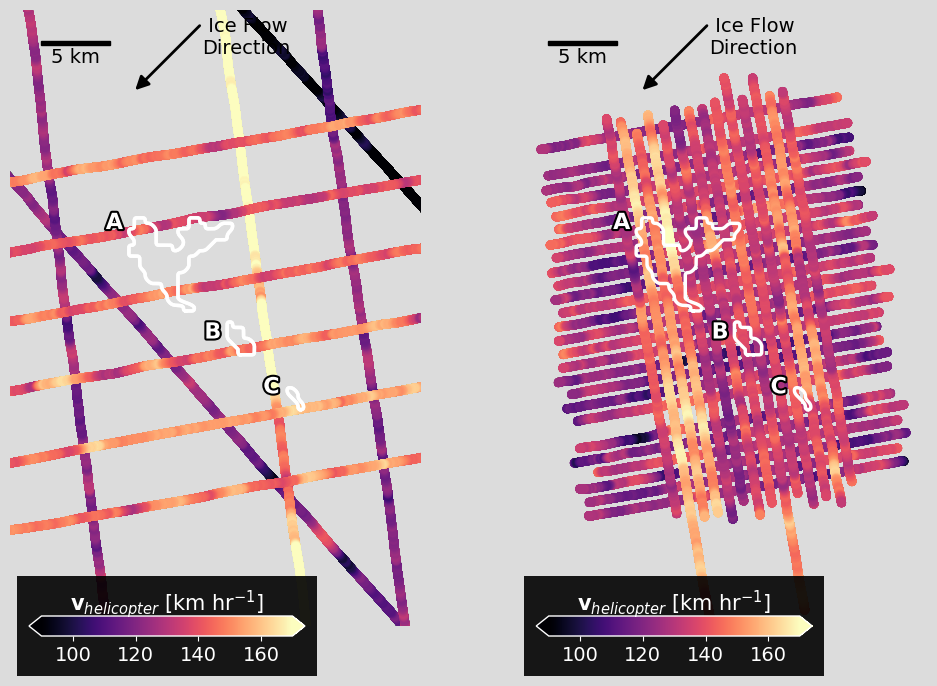

In [19]:
#################
### Figure S3 ###
#################

# Velocity plots

# Plot velocities
ps71_projection = ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-71)
fig, (ax,ax2) = plt.subplots(1,2,figsize=(12,8), subplot_kw={'projection': ps71_projection})

scalebar = AnchoredSizeBar(ax.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
ax.add_artist(scalebar)

#bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent
# Glacial Flow Direction Arrow
ax.annotate(
    '',
    xy=(659000, -1436000),      # arrow tip (downstream)
    xytext=(664000, -1431000),  # arrow tail
    arrowprops=dict(
        arrowstyle='-|>',       # filled arrow head
        color='black',
        lw=2,
        mutation_scale=20 ,      # controls head size
    ),
    transform=ps71_projection,
    zorder=10
)

ax.text(664000, -1432000, ' Ice Flow\nDirection',
        fontsize=14, color='black', ha='left', va='center',zorder=10)

bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent

# Remove borders
ax.patch.set_facecolor("none")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

for x, y in zip(xs_lake, ys_lake):
    ax.plot(x, y, color='white', linewidth=2.5, zorder=5)

# Add colorbar
k_cbar_anchor = (0,0)
cbbox = inset_axes(ax, width=3,height=1,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.9])

for radargram in offset_video_radargrams_1617[:]:
    #if 'Y' in radargram.transect_id.split('/')[-1]:
    cb = ax.scatter(radargram['x'],radargram['y'] , c=radargram['velocity'] * MS_TO_KMHR, cmap='magma', s=30, zorder=4,vmin=90,vmax=170)
cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal',extend='both') #make colorbar
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label(r"$\mathbf{v}_{helicopter}$ [km hr$^{-1}$]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

#cbar.ax.minorticks_on()

ax.set_xlim(bbox[0],bbox[2])
ax.set_ylim(bbox[1],bbox[3])
#ax.set_title(f"Window = {win_m} m, Overlap = {ovlp_m} m", fontsize=16)


# Label lakes A, B, C
ax.annotate('A', xy=(657000, -1446000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax.annotate('B', xy=(664200, -1454000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection, zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax.annotate('C', xy=(668500, -1458000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])

# Ax2
scalebar = AnchoredSizeBar(ax2.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
ax2.add_artist(scalebar)

#bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent
# Glacial Flow Direction Arrow
ax2.annotate(
    '',
    xy=(659000, -1436000),      # arrow tip (downstream)
    xytext=(664000, -1431000),  # arrow tail
    arrowprops=dict(
        arrowstyle='-|>',       # filled arrow head
        color='black',
        lw=2,
        mutation_scale=20 ,      # controls head size
    ),
    transform=ps71_projection,
    zorder=10
)

ax2.text(664000, -1432000, ' Ice Flow\nDirection',
        fontsize=14, color='black', ha='left', va='center',zorder=10)

bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent

# Remove borders
ax2.patch.set_facecolor("none")
for spine in ax2.spines.values():
    spine.set_visible(False)
ax2.set_xticks([])
ax2.set_yticks([])

for x, y in zip(xs_lake, ys_lake):
    ax.plot(x, y, color='white', linewidth=2.5, zorder=5)

# Add colorbar
k_cbar_anchor = (0,0)
cbbox = inset_axes(ax2, width=3,height=1,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax2.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.9])

for radargram in offset_video_radargrams_1819[:]:
    #if 'Y' in radargram.transect_id.split('/')[-1]:
    cb = ax2.scatter(radargram['x'],radargram['y'] , c=radargram['velocity'] * MS_TO_KMHR, cmap='magma', s=30, zorder=4,vmin=90,vmax=170)
cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal', extend='both') #make colorbar
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label(r"$\mathbf{v}_{helicopter}$ [km hr$^{-1}$]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

#cbar.ax.minorticks_on()

ax2.set_xlim(bbox[0],bbox[2])
ax2.set_ylim(bbox[1],bbox[3])
#ax.set_title(f"Window = {win_m} m, Overlap = {ovlp_m} m", fontsize=16)

for x, y in zip(xs_lake, ys_lake):
    ax2.plot(x, y, color='white', linewidth=2.5, zorder=5)

# Label lakes A, B, C
ax2.annotate('A', xy=(657000, -1446000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax2.annotate('B', xy=(664200, -1454000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection, zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])
ax2.annotate('C', xy=(668500, -1458000), color='white', fontsize=16, fontweight='bold',transform=ps71_projection,zorder=10,path_effects=[pe.withStroke(linewidth=3, foreground='black')])

# Set background gainsboro
fig.patch.set_facecolor('gainsboro')

fig.savefig(os.path.join(outdir, 'FigureS3.png'), dpi=300, bbox_inches='tight')

972 972 972 972
0.0 21.689226030116767
0.0 22.963864853502923


/tmp/ipykernel_45678/2309483073.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


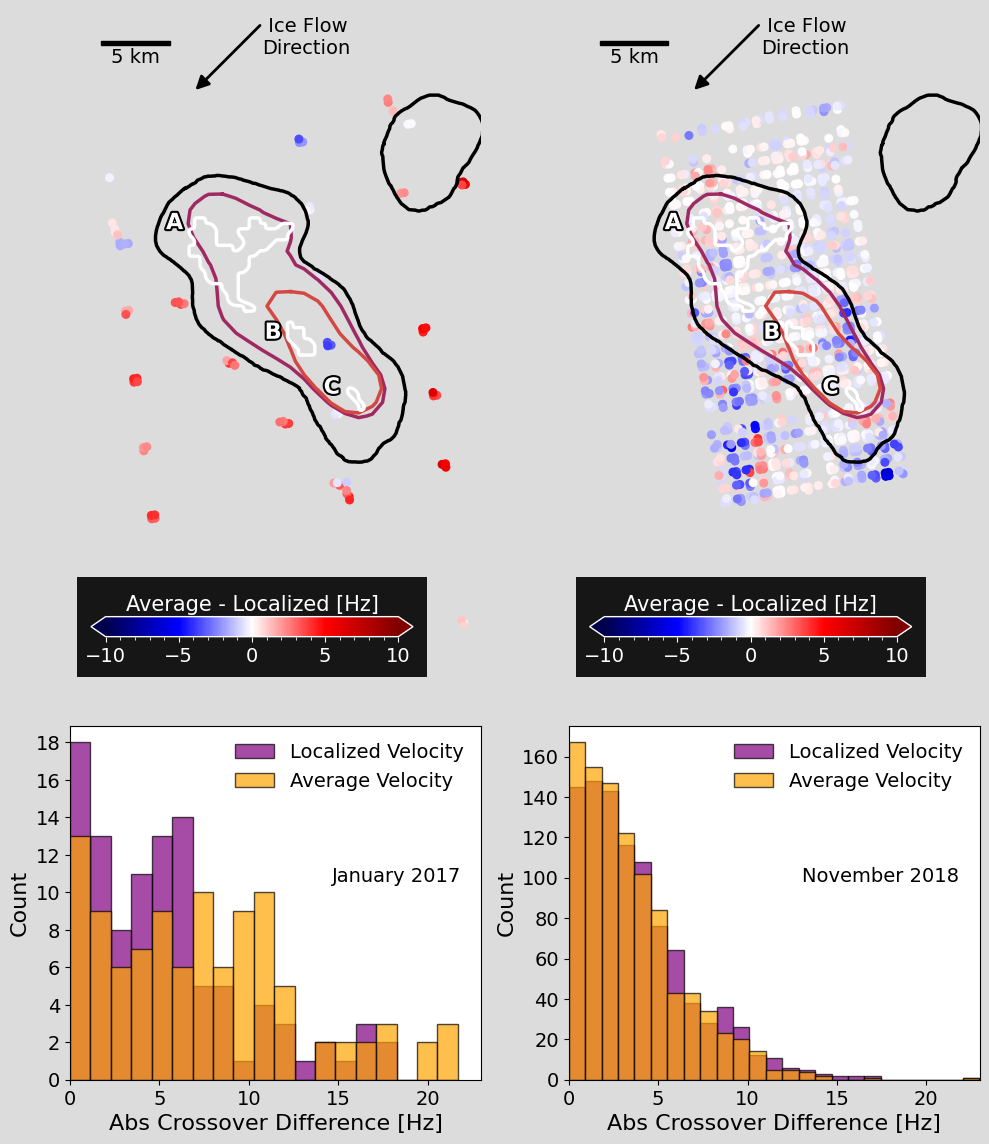

In [20]:
#################
### Figure S4 ###
#################

def common_panel_elements_S3(ax, plot_dict, rad_vel):
    """
    Plot doppler width and lake outline map view.
    """

    bbox = [650000,-1475000,680000,-1430000] #David_SGL2_full extent

    # Remove borders
    ax.patch.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlim(bbox[0],bbox[2])
    ax.set_ylim(bbox[1],bbox[3])
    
    scalebar = AnchoredSizeBar(ax.transData, 5000, '5 km', 'upper left', pad=1.5, color='black', frameon=False, size_vertical=300, fontproperties={'size': 14})
    ax.add_artist(scalebar)

    # Glacial flow arrow
    ax.annotate(
    '',
    xy=(659000, -1436000),      # Tip
    xytext=(664000, -1431000),  # Tail
    arrowprops=dict(
        arrowstyle='-|>',       
        color='black',
        lw=2,
        mutation_scale=20 ,     
    ),
    transform=ps71_projection,
    zorder=10
    )
    ax.text(664000, -1432000, ' Ice Flow\nDirection',
        fontsize=14, color='black', ha='left', va='center',zorder=10)

    return ax

# Two histograms, 2016-2017 and 2018-2019 next to double difference plots
ps71_projection = ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-71)
fig = plt.figure(figsize=(10, 12))
gs = fig.add_gridspec(2, 2,height_ratios=[2, 1])
ax1 = fig.add_subplot(gs[0, 0], projection=ps71_projection)
ax2 = fig.add_subplot(gs[0, 1], projection=ps71_projection)
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# Maps
common_panel_elements_S3(ax1, plotting_dict, offset_video_radargrams_1617)
plot_outlines(ax1, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)
cb = ax1.scatter(x_cross, y_cross, c=ridge_diff_1617-ridge_diff_velocity_corrected_1617, cmap='seismic', s=30, zorder=4,vmin=-10,vmax=10) 


common_panel_elements_S3(ax2, plotting_dict_1819, offset_video_radargrams_1819)
plot_outlines(ax2, evolving_outlines, DDInSAR_outlines, idx_1617, idx_1819)
print(len(x_cross_1819), len(y_cross_1819), len(ridge_diff_1819), len(ridge_diff_velocity_corrected_1819))
cb = ax2.scatter(x_cross_1819, y_cross_1819, c=ridge_diff_1819-ridge_diff_velocity_corrected_1819, cmap='seismic', s=30, zorder=4,vmin=-10,vmax=10)

fig.set_facecolor('gainsboro')

# Add colorbar
k_cbar_anchor = (0,0)
cbbox = inset_axes(ax1, width=3.5,height=1,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax1.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.9])
cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal', extend='both') #make colorbar
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label("Average - Localized [Hz]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

cbar.ax.minorticks_on()
cbar.ax.tick_params(axis='x', which='minor',color='white')

# Add colorbar
k_cbar_anchor = (0,0)
cbbox = inset_axes(ax2, width=3.5,height=1,
                bbox_to_anchor=k_cbar_anchor,
                bbox_transform=ax2.transAxes, loc="center left")
[cbbox.spines[k].set_visible(False) for k in cbbox.spines]
cbbox.tick_params(
    axis = 'both',
    left = False,
    top = False,
    right = False,
    bottom = False,
    labelleft = False,
    labeltop = False,
    labelright = False,
    labelbottom = False
)
cbbox.set_facecolor([0,0,0,0.9])
cbaxes = inset_axes(cbbox, '92%', '20%', loc = 'center')
cbar=fig.colorbar(cb,cax=cbaxes, orientation='horizontal',extend='both') #make colorbar
cbar.outline.set_edgecolor('white')
cbar.outline.set_linewidth(1)
cbar.ax.tick_params(labelsize=14, color='white', labelcolor='white')
cbar.set_label("Average - Localized [Hz]", fontsize=15, color='white')
cbar.ax.xaxis.set_label_position('top')

cbar.ax.minorticks_on()
# White minorticks
cbar.ax.tick_params(axis='x', which='minor',color='white')






# Histograms
# Combine data to get common bins
all_data = np.concatenate([ridge_diff_velocity_corrected_1617, ridge_diff_1617])
bins = np.linspace(all_data.min(), all_data.max(), 20) 
print(all_data.min(), all_data.max())
ax3.hist(ridge_diff_velocity_corrected_1617, bins=bins, color='purple',alpha=0.7, edgecolor='black')
ax3.hist(ridge_diff_1617, bins=bins, color='orange',alpha=0.7, edgecolor='black')
# Boxplot
#ax.boxplot(abs_ridge_diff, vert=False, patch_artist=True, boxprops=dict(facecolor='purple', color='black'), medianprops=dict(color='yellow'))
ax3.set_xlabel('Abs Crossover Difference [Hz]', fontsize=16)
ax3.set_ylabel('Count', fontsize=16)
ax3.tick_params(labelsize=14)
ax3.text(0.95, 0.6, f'January 2017', transform=ax3.transAxes, fontsize=14, verticalalignment='top', horizontalalignment='right')

ax3.legend(['Localized Velocity', 'Average Velocity'], fontsize=14, loc='upper right', frameon=False)
ax3.set_xlim(0, 23)
ax3.set_yticks(np.arange(0, 20, 2))

# Combine data to get common bins
all_data = np.concatenate([ridge_diff_velocity_corrected_1819, ridge_diff_1819])
bins = np.linspace(all_data.min(), all_data.max(), 26) 
print(all_data.min(), all_data.max())
ax4.hist(ridge_diff_velocity_corrected_1819, bins=bins, color='purple',alpha=0.7, edgecolor='black')
ax4.hist(ridge_diff_1819, bins=bins, color='orange',alpha=0.7, edgecolor='black')
# Boxplot
#ax.boxplot(abs_ridge_diff, vert=False, patch_artist=True, boxprops=dict(facecolor='purple', color='black'), medianprops=dict(color='yellow'))
ax4.set_xlabel('Abs Crossover Difference [Hz]', fontsize=16)
ax4.set_ylabel('Count', fontsize=16)
ax4.tick_params(labelsize=14)
ax4.set_xlim(0, 23)
ax4.text(0.95, 0.6, f'November 2018', transform=ax4.transAxes, fontsize=14, verticalalignment='top', horizontalalignment='right')

ax4.legend(['Localized Velocity', 'Average Velocity'], fontsize=14, loc='upper right', frameon=False)

# Pad bottom row for y axis labels
plt.tight_layout()
plt.subplots_adjust(hspace=0.1)
fig.savefig(os.path.join(outdir, 'FigureS4.png'), dpi=300, bbox_inches='tight')